# Notebook 03: Rentabilidad de la cartera

**Pregunta de negocio:** ¿la tasa de interés cobrada compensa el riesgo de cada segmento? ¿Dónde gana y dónde pierde plata la cartera?

**Base:** 589.488 préstamos limpios (ver notebooks 01 y 02).


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/prestamos_limpios.csv", parse_dates=["issue_d"])
print(df.shape)

(589488, 25)


In [2]:
componentes = df["total_rec_prncp"] + df["total_rec_int"] + df["total_rec_late_fee"]
dif_con_recuperos = (df["total_pymnt"] - (componentes + df["recoveries"])).abs()
dif_sin_recuperos = (df["total_pymnt"] - componentes).abs()

print("Diferencia máxima incluyendo recuperos:", round(dif_con_recuperos.max(), 2))
print("Diferencia máxima sin incluir recuperos:", round(dif_sin_recuperos.max(), 2))

Diferencia máxima incluyendo recuperos: 0.01
Diferencia máxima sin incluir recuperos: 34294.1


## Verificación: ¿qué incluye `total_pymnt`?

Se concilió `total_pymnt` contra la suma de sus componentes. La diferencia máxima es de 0,01 si se incluyen los recuperos y de 34.294,10 si no se incluyen. **Conclusión:** `total_pymnt` ya incluye los recuperos; sumarlos de nuevo los duplicaría.

**Definición de rentabilidad:**
- Cobrado neto = `total_pymnt` − `collection_recovery_fee` (gasto de cobranza)
- Resultado = cobrado neto − `loan_amnt`
- Retorno = resultado ÷ `loan_amnt`

**Limitaciones:** retorno total sobre la vida del préstamo (no anualizado); no descuenta costo de fondeo, valor tiempo del dinero ni comisiones de la plataforma.

In [3]:
df["cobrado_neto"] = df["total_pymnt"] - df["collection_recovery_fee"]
df["resultado"] = df["cobrado_neto"] - df["loan_amnt"]

print("Capital prestado:", round(df["loan_amnt"].sum() / 1e6, 1), "millones")
print("Cobrado neto:", round(df["cobrado_neto"].sum() / 1e6, 1), "millones")
print("Resultado:", round(df["resultado"].sum() / 1e6, 1), "millones")
print("Retorno sobre lo prestado:", round(df["resultado"].sum() / df["loan_amnt"].sum() * 100, 2), "%")

Capital prestado: 7450.2 millones
Cobrado neto: 8051.6 millones
Resultado: 601.4 millones
Retorno sobre lo prestado: 8.07 %


In [4]:
por_estado = df.groupby("loan_status").agg(prestamos=("loan_amnt", "size"), prestado=("loan_amnt", "sum"), cobrado=("cobrado_neto", "sum"), resultado=("resultado", "sum"))
por_estado["cobrado_sobre_prestado_%"] = (por_estado["cobrado"] / por_estado["prestado"] * 100).round(1)
por_estado[["prestado", "cobrado", "resultado"]] = (por_estado[["prestado", "cobrado", "resultado"]] / 1e6).round(1)
por_estado

,prestamos,prestado,cobrado,resultado,cobrado_sobre_prestado_%
loan_status,,,,,
Charged Off,82728,1013.9,634.4,-379.5,62.6
Fully Paid,506760,6436.3,7417.2,980.8,115.2


In [5]:
por_grade = df.groupby("grade").agg(prestado=("loan_amnt", "sum"), resultado=("resultado", "sum"), tasa_default=("default", "mean"), tasa_interes=("int_rate", "mean"))
por_grade["retorno_%"] = (por_grade["resultado"] / por_grade["prestado"] * 100).round(2)
por_grade["tasa_default"] = (por_grade["tasa_default"] * 100).round(2)
por_grade["tasa_interes"] = por_grade["tasa_interes"].round(2)
por_grade[["prestado", "resultado"]] = (por_grade[["prestado", "resultado"]] / 1e6).round(1)
por_grade

,prestado,resultado,tasa_default,tasa_interes,retorno_%
grade,,,,,
A,1901.9,137.5,5.45,7.21,7.23
B,2528.9,224.3,11.22,10.86,8.87
C,1866.0,157.0,18.03,13.94,8.41
D,862.4,66.1,23.57,17.26,7.66
E,245.7,14.2,28.92,19.98,5.78
F,39.5,2.1,33.14,23.90,5.38
G,5.9,0.2,40.17,26.27,3.32


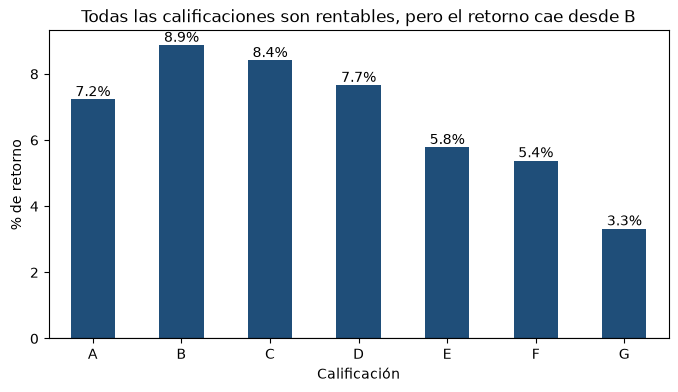

In [8]:
colores = ["#1f4e79" if v >= 0 else "#c0392b" for v in por_grade["retorno_%"]]
ax = por_grade["retorno_%"].plot(kind="bar", color=colores, figsize=(8, 4))
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Todas las calificaciones son rentables, pero el retorno cae desde B")
ax.set_xlabel("Calificación")
ax.set_ylabel("% de retorno")
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.xticks(rotation=0)
plt.show()

In [9]:
por_anio = df.groupby("anio").agg(prestado=("loan_amnt", "sum"), resultado=("resultado", "sum"), tasa_default=("default", "mean"))
por_anio["retorno_%"] = (por_anio["resultado"] / por_anio["prestado"] * 100).round(2)
por_anio["tasa_default"] = (por_anio["tasa_default"] * 100).round(2)
por_anio[["prestado", "resultado"]] = (por_anio[["prestado", "resultado"]] / 1e6).round(1)
por_anio

,prestado,resultado,tasa_default,retorno_%
anio,,,,
2012,507.8,51.3,13.58,10.10
2013,1272.1,139.3,12.33,10.95
2014,2046.0,180.5,13.73,8.82
2015,3624.3,230.3,14.89,6.35


In [10]:
mezcla = pd.crosstab(df["anio"], df["grade"], normalize="index").mul(100).round(1)
mezcla

grade,A,B,C,D,E,F,G
anio,,,,,,,
2012,24.7,38.7,22.8,11.7,1.8,0.2,0.1
2013,17.0,40.1,24.6,14.4,3.2,0.6,0.0
2014,21.7,32.9,27.1,12.6,4.3,1.2,0.1
2015,24.8,32.4,27.4,11.6,3.3,0.5,0.1
